# 第11章：小红书笔记热度预测模型

本章把热度建模为连续回归问题。目标变量为

$$y=\text{点赞数}+\text{收藏数}+4\times\text{评论数}.$$

为降低长尾分布和极端爆款对拟合的支配，所有模型学习
$\log(1+y)$，预测后再变换回原始互动量尺度。输入仅包含发布前可获得的
发布者、文本形式、情感、标签和时间特征，不使用点赞、收藏、评论等发布后信息。

## 11.1 实验设计

- 合并 `data/raw` 中三个业务压缩包的笔记详情 CSV，并按链接（无链接时按编号、标题和博主）去重。
- 固定随机种子，从有效样本中抽取至多 60,000 条，以 8:2 划分训练集与测试集。
- 比较中位数基线、线性回归、Ridge、随机森林、Extra Trees 和直方图梯度提升树。
- 使用相同样本、特征和测试集；缺失值填补参数只在训练集拟合。
- MAE/RMSE 衡量绝对误差，RMSLE 衡量相对量级误差，$R^2$ 衡量方差解释率，
  Spearman 衡量排序质量，Top 20% 召回率衡量模型找出真实高热帖的能力。

In [1]:
from __future__ import annotations

import io
import json
import re
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "raw").exists()
)
DATA_DIR = ROOT / "data" / "raw"
OUT = ROOT / "outputs" / "chapter11"
OUT.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42


def read_detail_csvs() -> pd.DataFrame:
    frames = []
    audit = []
    required = {"文案（标题）", "文案（正文）", "相对准确点赞数", "相对准确评论数", "相对准确收藏数"}
    for archive in sorted(DATA_DIR.glob("*.zip")):
        with zipfile.ZipFile(archive) as zf:
            for member in zf.infolist():
                if not member.filename.lower().endswith(".csv") or member.file_size == 0:
                    continue
                try:
                    frame = pd.read_csv(io.BytesIO(zf.read(member)), encoding="utf-8-sig", low_memory=False)
                except Exception:
                    continue
                if not required.issubset(frame.columns):
                    continue
                frame["数据来源"] = archive.stem
                frames.append(frame)
                audit.append({"压缩包": archive.name, "文件": member.filename, "行数": len(frame)})
    if not frames:
        raise RuntimeError("没有找到包含所需字段的笔记详情 CSV。")
    pd.DataFrame(audit).to_csv(OUT / "11_1_data_file_audit.csv", index=False, encoding="utf-8-sig")
    return pd.concat(frames, ignore_index=True)


def num(frame: pd.DataFrame, col: str) -> pd.Series:
    return pd.to_numeric(frame[col], errors="coerce")


def prepare(df: pd.DataFrame):
    raw_rows = len(df)
    if "具体链接" in df:
        link = df["具体链接"].astype("string").str.strip()
        has_link = link.notna() & link.ne("") & link.ne("nan")
        linked = df.loc[has_link].drop_duplicates("具体链接")
        fallback = [c for c in ["编号", "文案（标题）", "博主名称"] if c in df.columns]
        unlinked = df.loc[~has_link].drop_duplicates(fallback)
        df = pd.concat([linked, unlinked], ignore_index=True)

    likes = num(df, "相对准确点赞数")
    comments = num(df, "相对准确评论数")
    favs = num(df, "相对准确收藏数")
    fans = num(df, "相对准确粉丝数") if "相对准确粉丝数" in df else num(df, "粉丝量")
    valid = likes.notna() & comments.notna() & favs.notna()
    valid &= (likes >= 0) & (comments >= 0) & (favs >= 0)
    df = df.loc[valid].copy()
    likes, comments, favs, fans = likes.loc[valid], comments.loc[valid], favs.loc[valid], fans.loc[valid]
    y = (likes + favs + 4 * comments).astype(float)

    title = df["文案（标题）"].fillna("").astype(str)
    body = df["文案（正文）"].fillna("").astype(str)
    tags = df["标签词"].fillna("").astype(str) if "标签词" in df else pd.Series("", index=df.index)
    text = title + " " + body
    post_date = pd.to_datetime(df.get("推断笔记发布日期", df.get("笔记发布日期")), errors="coerce")
    emotion = num(df, "情感预测") if "情感预测" in df else pd.Series(np.nan, index=df.index)

    X = pd.DataFrame(index=df.index)
    X["log_fans"] = np.log1p(fans.clip(lower=0))
    X["title_len"] = title.str.len()
    X["body_len"] = body.str.len()
    X["tag_count"] = tags.apply(lambda s: len([x for x in re.split(r"[,，#\s]+", s) if x]))
    X["exclamation_count"] = text.str.count(r"[!！]")
    X["question_count"] = text.str.count(r"[?？]")
    X["emoji_count"] = text.apply(lambda s: len(re.findall(r"[\U0001F300-\U0001FAFF]", s)))
    X["emotion_positive"] = emotion
    X["weekday"] = post_date.dt.dayofweek
    location = df.get("笔记发布地", pd.Series("", index=df.index)).fillna("").astype(str).str.strip()
    X["has_location"] = (~location.isin(["", "nan", "-9999"])).astype(int)

    X, y = X.reset_index(drop=True), y.reset_index(drop=True)
    metadata = {
        "raw_rows": int(raw_rows),
        "deduplicated_usable_rows": int(len(X)),
        "features": list(X.columns),
        "target_definition": "点赞数 + 收藏数 + 4×评论数",
        "target_median": float(y.median()),
        "target_mean": float(y.mean()),
        "target_p80": float(y.quantile(0.8)),
        "target_p95": float(y.quantile(0.95)),
        "target_max": float(y.max()),
    }
    return X, y, metadata


def log_target(regressor):
    return TransformedTargetRegressor(
        regressor=regressor, func=np.log1p, inverse_func=np.expm1, check_inverse=False
    )


def evaluate(y_true, pred):
    pred = np.clip(np.asarray(pred), 0, None)
    y_array = np.asarray(y_true)
    k = max(1, int(np.ceil(0.20 * len(y_array))))
    true_top_idx = np.argsort(y_array, kind="stable")[-k:]
    pred_top_idx = np.argsort(pred, kind="stable")[-k:]
    top_overlap = np.intersect1d(true_top_idx, pred_top_idx).size
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": mean_squared_error(y_true, pred) ** 0.5,
        "RMSLE": mean_squared_log_error(y_true, pred) ** 0.5,
        "R2": r2_score(y_true, pred),
        "Spearman": spearmanr(y_true, pred).statistic,
        "Top20Recall": top_overlap / k,
    }

In [2]:
df = read_detail_csvs()
X, y, metadata = prepare(df)

if len(X) > 60000:
    bins = pd.qcut(np.log1p(y), q=10, duplicates="drop")
    X, _, y, _ = train_test_split(
        X, y, train_size=60000, stratify=bins, random_state=RANDOM_STATE
    )
    X, y = X.reset_index(drop=True), y.reset_index(drop=True)
metadata["modeling_rows"] = int(len(X))

y_bins = pd.qcut(np.log1p(y), q=10, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y_bins, random_state=RANDOM_STATE
)

scaled = [
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
]
models = {
    "中位数基线": DummyRegressor(strategy="median"),
    "线性回归": log_target(Pipeline(scaled + [("model", LinearRegression())])),
    "Ridge": log_target(Pipeline(scaled + [("model", Ridge(alpha=10.0))])),
    "随机森林": log_target(Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=250, min_samples_leaf=4, max_features=0.8,
            n_jobs=-1, random_state=RANDOM_STATE
        )),
    ])),
    "Extra Trees": log_target(Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(
            n_estimators=250, min_samples_leaf=4, max_features=0.8,
            n_jobs=-1, random_state=RANDOM_STATE
        )),
    ])),
    "梯度提升树": log_target(Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=300, learning_rate=0.06, max_leaf_nodes=31,
            l2_regularization=1.0, random_state=RANDOM_STATE
        )),
    ])),
}

rows, fitted, predictions = [], {}, {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    pred = np.clip(model.predict(X_test), 0, None)
    rows.append({"模型": name, **evaluate(y_test, pred), "训练秒数": time.perf_counter() - start})
    fitted[name], predictions[name] = model, pred

metrics = pd.DataFrame(rows).sort_values(["RMSLE", "Spearman"], ascending=[True, False])
metrics.to_csv(OUT / "11_2_to_11_5_regression_metrics.csv", index=False, encoding="utf-8-sig")

best_name = metrics.loc[metrics["模型"] != "中位数基线"].iloc[0]["模型"]
best_pred = predictions[best_name]
pd.DataFrame({"真实热度": y_test.to_numpy(), "预测热度": best_pred}).to_csv(
    OUT / "11_5_best_model_predictions.csv", index=False, encoding="utf-8-sig"
)

perm = permutation_importance(
    fitted[best_name], X_test, y_test, scoring="neg_mean_squared_log_error",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "特征": X.columns, "重要性均值": perm.importances_mean, "重要性标准差": perm.importances_std
}).sort_values("重要性均值", ascending=False)
importance.to_csv(OUT / "11_4_permutation_importance.csv", index=False, encoding="utf-8-sig")

metadata.update({
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "best_model_by_rmsle": best_name,
})
with open(OUT / "11_1_experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(9, 5.5))
p = metrics.sort_values("RMSLE", ascending=False)
ax.barh(p["模型"], p["RMSLE"], color="#B6574B")
ax.set(xlabel="RMSLE（越低越好）", title="第11章热度回归模型测试集表现")
for i, v in enumerate(p["RMSLE"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
fig.tight_layout()
fig.savefig(OUT / "11_model_rmsle.png", dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.5, 6))
sample = np.random.default_rng(RANDOM_STATE).choice(len(y_test), min(4000, len(y_test)), replace=False)
ax.scatter(np.log1p(y_test.to_numpy()[sample]), np.log1p(best_pred[sample]), s=9, alpha=0.25, color="#355C7D")
limit = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, limit], [0, limit], "--", color="#B6574B", linewidth=1)
ax.set(xlabel="log(1+真实热度)", ylabel="log(1+预测热度)", title=f"{best_name}：真实值与预测值")
fig.tight_layout()
fig.savefig(OUT / "11_best_model_actual_vs_predicted.png", dpi=180)
plt.close(fig)

print(json.dumps(metadata, ensure_ascii=False, indent=2))
display(metrics.style.format({
    "MAE": "{:,.1f}", "RMSE": "{:,.1f}", "RMSLE": "{:.3f}",
    "R2": "{:.3f}", "Spearman": "{:.3f}", "Top20Recall": "{:.3f}", "训练秒数": "{:.2f}"
}))
display(importance.style.format({"重要性均值": "{:.4f}", "重要性标准差": "{:.4f}"}))

C:\Users\fire\AppData\Local\Temp\ipykernel_2632\2929280799.py:137: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "Spearman": spearmanr(y_true, pred).statistic,


C:\Users\fire\miniconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\fire\miniconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


{
  "raw_rows": 323598,
  "deduplicated_usable_rows": 199473,
  "features": [
    "log_fans",
    "title_len",
    "body_len",
    "tag_count",
    "exclamation_count",
    "question_count",
    "emoji_count",
    "emotion_positive",
    "weekday",
    "has_location"
  ],
  "target_definition": "点赞数 + 收藏数 + 4×评论数",
  "target_median": 346.0,
  "target_mean": 3298.209527103919,
  "target_p80": 2134.0,
  "target_p95": 12755.0,
  "target_max": 1711417.0,
  "modeling_rows": 60000,
  "train_rows": 48000,
  "test_rows": 12000,
  "best_model_by_rmsle": "梯度提升树"
}


,模型,MAE,RMSE,RMSLE,R2,Spearman,Top20Recall,训练秒数
5,梯度提升树,"3,119.2","19,729.9",1.849,-0.002,0.515,0.429,2.97
4,Extra Trees,"3,125.5","19,698.1",1.862,0.001,0.509,0.429,2.40
3,随机森林,"3,124.6","19,666.2",1.866,0.004,0.506,0.424,6.39
2,Ridge,"3,149.1","19,797.5",1.936,-0.009,0.463,0.407,0.09
1,线性回归,"3,149.1","19,797.5",1.936,-0.009,0.463,0.407,0.10
0,中位数基线,"3,262.8","19,937.2",2.230,-0.023,nan,0.194,0.01


,特征,重要性均值,重要性标准差
0,log_fans,2.6196,0.0460
8,weekday,0.1541,0.0039
2,body_len,0.1359,0.0100
7,emotion_positive,0.1357,0.0134
9,has_location,0.1046,0.0078
3,tag_count,0.0668,0.0037
1,title_len,0.0513,0.0046
6,emoji_count,0.0190,0.0053
4,exclamation_count,0.0151,0.0042
5,question_count,-0.0000,0.0012


## 11.2 结果解读

模型表中的 MAE 和 RMSE 受极端爆款影响明显；长尾社交媒体数据不应只依据这两个指标选型。
本章以 RMSLE 为主要误差指标，以 Spearman 和 Top 20% 召回率检查排序与运营筛选能力。
中位数基线用于判断复杂模型是否真正提取到发布前信号。排列重要性在固定测试集上计算，
其数值表示打乱单项特征后模型对数误差的平均恶化程度。

需要特别注意：发布前特征无法解释平台临时流量分配、站外事件和偶然传播，因此模型更适合
做相对热度排序和候选筛选，而不应把单条笔记的点预测理解为确定性承诺。

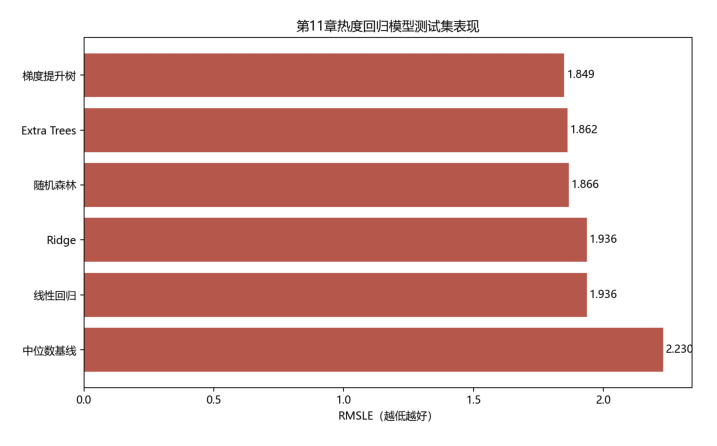

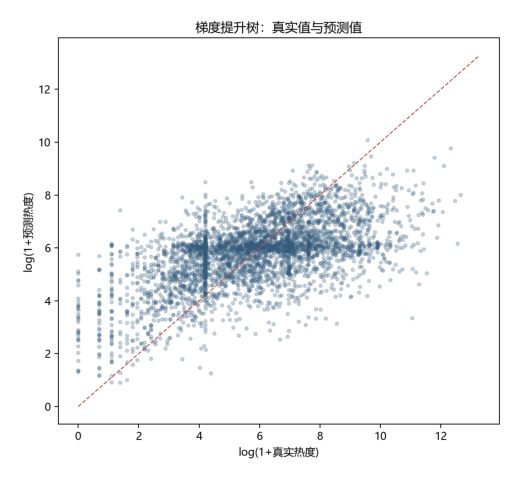

In [3]:
for image_name in ["11_model_rmsle.png", "11_best_model_actual_vs_predicted.png"]:
    img = plt.imread(OUT / image_name)
    plt.figure(figsize=(9, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()